# Lab 2 — TF-IDF Normalization & Classifier Comparison

This notebook combines the validated feature-generation design from `01_normalized_tfidf.ipynb`
with the working One-vs-Rest training/comparison design from `02_train_compare.ipynb`.

It evaluates **6 combinations** of TF and IDF weighting for Indic language identification:

1. Raw TF + standard IDF
2. Raw TF + normalized IDF
3. Sentence-length-normalized TF + standard IDF
4. Sentence-length-normalized TF + normalized IDF
5. Max-word-frequency-normalized TF + standard IDF
6. Max-word-frequency-normalized TF + normalized IDF

Constraints:
- No scikit-learn is used.
- TF, IDF, sparse feature construction, logistic regression, and Macro-F1 are implemented from scratch.
- Vocabulary and DF statistics are learned from the training set only.
- The same vocabulary, tokenizer, train/validation/test split, and raw feature counts are reused for all six combinations.
- No final row-wise L2 normalization is applied in Lab 2, because it would cancel the requested per-document TF normalization.


## Mathematical Formulations

For term $t$ in sentence/document $d$:

- $f_{t,d}$: raw frequency of term $t$.
- $|W(d)|$: total number of word tokens in sentence $d$.
- $\max_w f_{w,d}$: frequency of the most frequent word in sentence $d$.
- $N$: number of training sentences.
- $df(t)$: number of training sentences containing term $t$.
- $M$: maximum document frequency among word-unigram features in the training vocabulary.

### TF variants

**1. Raw TF**
$$TF_{raw}(t,d)=f_{t,d}$$

**2. Sentence-length normalized TF**
$$TF_{len}(t,d)=\frac{f_{t,d}}{|W(d)|}$$

**3. Maximum-word-frequency normalized TF**
$$TF_{max}(t,d)=\frac{f_{t,d}}{\max_w f_{w,d}}$$

### IDF variants

**1. Standard smoothed IDF**
$$IDF_{std}(t)=\ln\left(\frac{1+N}{1+df(t)}\right)+1$$

**2. Max-DF normalized IDF**

Following the validated `01_normalized_tfidf.ipynb`:
$$IDF_{maxdf}(t)=\ln\left(\frac{M}{df(t)}\right)$$

where $M$ is the document frequency of the most frequent **word unigram** in the training
vocabulary.

### Final feature weight

$$TFIDF(t,d)=TF(t,d)\times IDF(t)$$

No additional row-wise L2 normalization is applied.


## Section 1 — Setup & Data Splitting

We reuse the exact Lab 1 sentence dataset and perform the same stratified 80/10/10 split.
The six experiments use the same split so that only the TF/IDF weighting changes.


In [1]:
import re
import os
import csv
import math
import time
import random
from collections import defaultdict, Counter
from typing import List, Tuple, Dict, Optional

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATA_PATH = "../LAB1(30-7-26)/data/sentences.csv"

# Same 23-language dataset used in Lab 1.
LANGUAGE_CONFIGS = [
    "asm_Beng", "ben_Beng", "brx_Deva", "doi_Deva", "gom_Deva", "guj_Gujr",
    "hin_Deva", "kan_Knda", "kas_Arab", "kas_Deva", "mai_Deva", "mal_Mlym",
    "mar_Deva", "mni_Beng", "mni_Mtei", "npi_Deva", "ory_Orya", "pan_Guru",
    "san_Deva", "sat_Olck", "snd_Arab", "tam_Taml", "tel_Telu", "urd_Arab"
]

def tokenize_sentences(paragraph: str, min_words: int = 3, min_len: int = 10, max_len: int = 500) -> List[str]:
    paragraph = paragraph.strip()
    if not paragraph:
        return []
    boundary = re.compile(r'(?<=[.?!\u0964\u0965\u06D4])\s+')
    parts = boundary.split(paragraph)
    sentences = []
    for part in parts:
        for sub in part.split("\n"):
            sub = sub.strip()
            if min_len <= len(sub) <= max_len:
                words = sub.split()
                if len(words) >= min_words:
                    sentences.append(sub)
    return sentences

def collect_and_build_dataset(target_per_lang: int = 1000, seed: int = 42) -> List[Tuple[str, str]]:
    from datasets import load_dataset
    all_data = []
    for lang in LANGUAGE_CONFIGS:
        print(f"Streaming dataset configurations for: {lang}...", end="", flush=True)
        try:
            ds = load_dataset(
                "ai4bharat/IndicCorpV2",
                "indiccorp_v2",
                data_dir=f"data/{lang}",
                split="train",
                streaming=True,
                trust_remote_code=True
            )
        except Exception as e:
            print(f" Failed: {e}")
            continue

        sentences = []
        for row in ds:
            text = (row.get("text") or "").strip()
            if not text:
                continue
            sentences.extend(tokenize_sentences(text))
            if len(sentences) >= target_per_lang * 3:
                break

        seen = set()
        unique = []
        for s in sentences:
            if s not in seen:
                seen.add(s)
                unique.append(s)

        rng = random.Random(seed)
        rng.shuffle(unique)
        selected = unique[:target_per_lang]
        print(f" Collected {len(selected)} sentences.")
        all_data.extend((s, lang) for s in selected)
    return all_data

def load_dataset(path: str) -> List[Tuple[str, str]]:
    paths_to_try = [
        path,
        "../LAB1(30-7-26)/data/sentences.csv",
        "LAB1(30-7-26)/data/sentences.csv",
        "c:/Users/krish/Desktop/LLMS/LAB1(30-7-26)/data/sentences.csv"
    ]

    valid_path = None
    for p in paths_to_try:
        if os.path.exists(p) and os.path.getsize(p) > 100:
            valid_path = p
            break

    if valid_path is not None:
        dataset = []
        with open(valid_path, "r", encoding="utf-8", newline="") as f:
            reader = csv.reader(f)
            next(reader, None)
            for row in reader:
                if len(row) >= 2:
                    dataset.append((row[0], row[1]))
        return dataset

    print("Cached sentences file not found or empty. Downloading/Streaming...")
    os.makedirs("../LAB1(30-7-26)/data", exist_ok=True)
    dataset = collect_and_build_dataset(target_per_lang=1000, seed=RANDOM_SEED)

    save_path = "../LAB1(30-7-26)/data/sentences.csv"
    with open(save_path, "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["text", "label"])
        writer.writerows(dataset)
    print(f"Saved dataset to {save_path}")
    return dataset

def perform_stratified_split(data: List[Tuple[str, str]], train_ratio=0.8, val_ratio=0.1, seed=42):
    rng = random.Random(seed)
    by_label = defaultdict(list)
    for text, label in data:
        by_label[label].append(text)

    train_data, val_data, test_data = [], [], []

    for label, texts in sorted(by_label.items()):
        rng.shuffle(texts)
        n = len(texts)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)

        train_data.extend((t, label) for t in texts[:n_train])
        val_data.extend((t, label) for t in texts[n_train:n_train + n_val])
        test_data.extend((t, label) for t in texts[n_train + n_val:])

    rng.shuffle(train_data)
    rng.shuffle(val_data)
    rng.shuffle(test_data)
    return train_data, val_data, test_data

raw_dataset = load_dataset(DATA_PATH)

# Guard against accidentally using an old/wrong cached dataset.
label_counts = Counter(label for _, label in raw_dataset)
print(f"Loaded {len(raw_dataset)} sentences across {len(label_counts)} labels.")
print("Per-label counts:", sorted(label_counts.items()))

if len(label_counts) != 23 or any(c != 1000 for c in label_counts.values()):
    print("WARNING: Expected 23 labels with 1000 sentences each for this lab.")

train_set, val_set, test_set = perform_stratified_split(raw_dataset, seed=RANDOM_SEED)

train_texts, train_labels = zip(*train_set)
val_texts, val_labels = zip(*val_set)
test_texts, test_labels = zip(*test_set)

classes = sorted(set(train_labels))
label_to_idx = {c: i for i, c in enumerate(classes)}

y_train = np.array([label_to_idx[l] for l in train_labels], dtype=np.int32)
y_val = np.array([label_to_idx[l] for l in val_labels], dtype=np.int32)
y_test = np.array([label_to_idx[l] for l in test_labels], dtype=np.int32)

print(f"Train size: {len(train_texts)} | Val size: {len(val_texts)} | Test size: {len(test_texts)}")


Loaded 23000 sentences across 23 labels.
Per-label counts: [('asm_Beng', 1000), ('ben_Beng', 1000), ('brx_Deva', 1000), ('doi_Deva', 1000), ('gom_Deva', 1000), ('guj_Gujr', 1000), ('hin_Deva', 1000), ('kan_Knda', 1000), ('kas_Arab', 1000), ('khasi', 1000), ('mai_Deva', 1000), ('mal_Mlym', 1000), ('mar_Deva', 1000), ('mni_Mtei', 1000), ('npi_Deva', 1000), ('ory_Orya', 1000), ('pan_Guru', 1000), ('san_Deva', 1000), ('santhali', 1000), ('snd_Deva', 1000), ('tam_Taml', 1000), ('tel_Telu', 1000), ('urd_Arab', 1000)]
Train size: 18400 | Val size: 2300 | Test size: 2300


## Section 2 — Feature Extraction Helpers
We define helper functions to extract word unigrams, word bigrams, and character n-grams (2, 3, and 4-grams).

In [2]:
def tokenize(text):
    """Same Lab 1 tokenizer: word 1/2-grams + character 2/3/4-grams."""
    text = text.strip()
    words = text.split()
    grams = []

    for w in words:
        grams.append("W1|" + w)

    for i in range(len(words) - 1):
        grams.append("W2|" + words[i] + " " + words[i + 1])

    for n in (2, 3, 4):
        for i in range(len(text) - n + 1):
            grams.append(f"C{n}|" + text[i:i + n])

    return grams

def get_all_ngrams(text: str) -> List[str]:
    return tokenize(text)

print("Sample features:", get_all_ngrams("यह एक परीक्षण है।")[:6])


Sample features: ['W1|यह', 'W1|एक', 'W1|परीक्षण', 'W1|है।', 'W2|यह एक', 'W2|एक परीक्षण']


## Section 3 — Custom TF-IDF Vectorizer with Normalizations
This vectorizer supports three different TF options and two different IDF options, fitting all parameters strictly on the training set.

In [3]:
class CustomTfidfVectorizer:
    """Custom TF-IDF feature builder for all six Lab 2 combinations.

    Vocabulary and IDF statistics are fit on training data only.
    No final row-wise L2 normalization is applied.
    """

    def __init__(self, min_df: int = 3, max_features: Optional[int] = 80000,
                 tf_mode: str = "raw", idf_mode: str = "unnorm"):
        self.min_df = min_df
        self.max_features = max_features
        self.tf_mode = tf_mode
        self.idf_mode = idf_mode
        self.vocab = {}
        self.idf = None
        self.n_docs = 0
        self.max_df_word = 0

    def fit(self, texts: List[str]) -> "CustomTfidfVectorizer":
        self.n_docs = len(texts)
        df_counter = Counter()
        word_df_counter = Counter()

        for text in texts:
            grams = set(tokenize(text))
            df_counter.update(grams)
            word_df_counter.update(
                g for g in grams if g.startswith("W1|")
            )

        vocab_terms = sorted(
            g for g, c in df_counter.items()
            if c >= self.min_df
        )

        # Deterministic vocabulary ordering, matching the reference notebook.
        vocab_terms.sort(key=lambda g: (-df_counter[g], g))

        if self.max_features is not None:
            vocab_terms = vocab_terms[:self.max_features]

        self.vocab = {g: i for i, g in enumerate(vocab_terms)}

        # M = maximum document frequency among WORD UNIGRAMS.
        word_dfs = [
            word_df_counter[g]
            for g in vocab_terms
            if g.startswith("W1|") and g in word_df_counter
        ]
        self.max_df_word = max(word_dfs) if word_dfs else self.n_docs

        df_arr = np.array(
            [df_counter[g] for g in vocab_terms],
            dtype=np.float64
        )

        if self.idf_mode == "unnorm":
            self.idf = np.log(
                (1.0 + self.n_docs) / (1.0 + df_arr)
            ) + 1.0

        elif self.idf_mode == "norm_max_df":
            # Exact formula used in 01_normalized_tfidf:
            # ln(M / df(t)), where M is max word-unigram DF.
            self.idf = np.log(
                self.max_df_word / df_arr
            )

        else:
            raise ValueError(f"Unknown IDF mode: {self.idf_mode}")

        return self

    def precompute_counts(self, texts: List[str]):
        per_doc_counts = []
        n_words_list = []
        max_word_freq_list = []

        for text in texts:
            grams = tokenize(text)
            raw_counts = Counter(grams)

            indexed = {}
            for gram, count in raw_counts.items():
                j = self.vocab.get(gram)
                if j is not None:
                    indexed[j] = count

            per_doc_counts.append(indexed)

            words = text.strip().split()
            n_words_list.append(float(len(words)) or 1.0)

            word_counts = Counter(words)
            max_word_freq_list.append(
                float(max(word_counts.values()))
                if word_counts else 1.0
            )

        return (
            per_doc_counts,
            np.array(n_words_list, dtype=np.float64),
            np.array(max_word_freq_list, dtype=np.float64)
        )

    def build_matrix(self, per_doc_counts, denom_array=None) -> sp.csr_matrix:
        rows, cols, data = [], [], []

        for row_idx, indexed in enumerate(per_doc_counts):
            if not indexed:
                continue

            denom = (
                denom_array[row_idx]
                if self.tf_mode != "raw"
                else 1.0
            )

            for j, count in indexed.items():
                tf = count / denom
                rows.append(row_idx)
                cols.append(j)
                data.append(tf * self.idf[j])

        return sp.csr_matrix(
            (data, (rows, cols)),
            shape=(len(per_doc_counts), len(self.vocab)),
            dtype=np.float64
        )

    def transform_from_counts(
        self,
        per_doc_counts,
        n_words,
        max_word_freq
    ) -> sp.csr_matrix:
        if self.tf_mode == "len":
            denom = n_words
        elif self.tf_mode == "max":
            denom = max_word_freq
        else:
            denom = None

        return self.build_matrix(per_doc_counts, denom)

    def transform(self, texts: List[str]) -> sp.csr_matrix:
        counts, n_words, max_word_freq = self.precompute_counts(texts)
        return self.transform_from_counts(
            counts, n_words, max_word_freq
        )


## Section 4 — Custom One-vs-Rest Logistic Regression
We use the working training design from `02_train_compare.ipynb`: 23 independent
binary logistic regressions trained together with vectorized full-batch gradient descent.
No sklearn classifier is used.


In [4]:
def sigmoid(z):
    out = np.empty_like(z, dtype=np.float64)
    pos = z >= 0

    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))

    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)

    return out


class OneVsRestLogisticRegression:
    def __init__(
        self,
        languages,
        lr: float = 0.5,
        reg: float = 10.0,
        epochs: int = 350
    ):
        self.languages = list(languages)
        self.lr = lr
        self.reg = reg
        self.epochs = epochs
        self.W = None
        self.b = None

    def _one_hot(self, y_labels):
        idx = {lang: i for i, lang in enumerate(self.languages)}
        Y = np.zeros(
            (len(y_labels), len(self.languages)),
            dtype=np.float64
        )

        for i, lab in enumerate(y_labels):
            Y[i, idx[lab]] = 1.0

        return Y

    def fit(self, X, y_labels):
        n, v = X.shape
        k = len(self.languages)

        # W: features x classes
        self.W = np.zeros((v, k), dtype=np.float64)
        self.b = np.zeros(k, dtype=np.float64)

        Y = self._one_hot(y_labels)
        Xt = X.T.tocsr()

        for epoch in range(1, self.epochs + 1):
            Z = X.dot(self.W) + self.b
            P = sigmoid(Z)

            G = P - Y

            gW = Xt.dot(G) / n + (self.reg / n) * self.W
            gb = G.mean(axis=0)

            self.W -= self.lr * gW
            self.b -= self.lr * gb

        return self

    def predict_proba(self, X):
        return sigmoid(X.dot(self.W) + self.b)

    def predict(self, X):
        P = self.predict_proba(X)
        return np.array(self.languages)[P.argmax(axis=1)]


## Section 5 — Custom Evaluation Metrics
We implement confusion matrix, per-class F1, and Macro-F1 from scratch.
No sklearn evaluation metric is used.


In [5]:
def compute_confusion_matrix(y_true, y_pred, languages):
    idx = {lang: i for i, lang in enumerate(languages)}
    cm = np.zeros((len(languages), len(languages)), dtype=np.int64)

    for true_label, pred_label in zip(y_true, y_pred):
        cm[idx[true_label], idx[pred_label]] += 1

    return cm


def calculate_macro_f1(y_true, y_pred, languages):
    cm = compute_confusion_matrix(y_true, y_pred, languages)
    f1_scores = []

    for i in range(len(languages)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

        f1 = (
            2.0 * precision * recall / (precision + recall)
            if precision + recall > 0
            else 0.0
        )

        f1_scores.append(f1)

    return float(np.mean(f1_scores)), np.array(f1_scores)


## Section 6 — Evaluating All 6 Combinations
We iterate through all combinations of term frequency (TF) and inverse document frequency (IDF) normalizations and train our classifier on each.

In [6]:
combinations = [
    {"name": "Combo 1: TF Raw & IDF Unnormalized", "tf": "raw", "idf": "unnorm"},
    {"name": "Combo 2: TF Raw & IDF Normalized", "tf": "raw", "idf": "norm_max_df"},
    {"name": "Combo 3: TF Total Words & IDF Unnormalized", "tf": "len", "idf": "unnorm"},
    {"name": "Combo 4: TF Total Words & IDF Normalized", "tf": "len", "idf": "norm_max_df"},
    {"name": "Combo 5: TF Max Word Freq & IDF Unnormalized", "tf": "max", "idf": "unnorm"},
    {"name": "Combo 6: TF Max Word Freq & IDF Normalized", "tf": "max", "idf": "norm_max_df"},
]

# Fit one shared vocabulary/DF basis on TRAINING data for the entire experiment.
base_vectorizer = CustomTfidfVectorizer(
    min_df=3,
    max_features=80000,
    tf_mode="raw",
    idf_mode="unnorm"
)
base_vectorizer.fit(list(train_texts))

train_counts, train_nwords, train_maxword = base_vectorizer.precompute_counts(list(train_texts))
val_counts, val_nwords, val_maxword = base_vectorizer.precompute_counts(list(val_texts))
test_counts, test_nwords, test_maxword = base_vectorizer.precompute_counts(list(test_texts))

results = []
per_language_f1 = {}

for idx, combo in enumerate(combinations, 1):
    print(f"\nEvaluating Combo {idx}: {combo['name']} ...")

    # Reuse exactly the same vocabulary and raw counts across all six combinations.
    vectorizer = CustomTfidfVectorizer(
        min_df=3,
        max_features=80000,
        tf_mode=combo["tf"],
        idf_mode=combo["idf"]
    )
    vectorizer.vocab = base_vectorizer.vocab
    vectorizer.n_docs = base_vectorizer.n_docs
    vectorizer.max_df_word = base_vectorizer.max_df_word

    # Use the shared training DF values to calculate the selected IDF.
    vocab_terms = [None] * len(base_vectorizer.vocab)
    for gram, j in base_vectorizer.vocab.items():
        vocab_terms[j] = gram

    # Recover DF from training document counts, exactly from the shared vocabulary.
    df_values = np.zeros(len(vocab_terms), dtype=np.float64)
    for indexed in train_counts:
        for j in indexed:
            df_values[j] += 1.0

    if combo["idf"] == "unnorm":
        vectorizer.idf = np.log(
            (1.0 + base_vectorizer.n_docs) / (1.0 + df_values)
        ) + 1.0
    else:
        vectorizer.idf = np.log(
            base_vectorizer.max_df_word / df_values
        )

    vectorizer.min_df = 3
    vectorizer.max_features = 80000

    def build_from_shared(counts, nwords, maxword):
        if combo["tf"] == "len":
            denom = nwords
        elif combo["tf"] == "max":
            denom = maxword
        else:
            denom = None

        return vectorizer.build_matrix(counts, denom)

    X_train = build_from_shared(train_counts, train_nwords, train_maxword)
    X_val = build_from_shared(val_counts, val_nwords, val_maxword)
    X_test = build_from_shared(test_counts, test_nwords, test_maxword)

    print(
        f"  Feature matrix shapes: "
        f"train={X_train.shape}, val={X_val.shape}, test={X_test.shape}"
    )

    t0 = time.time()

    clf = OneVsRestLogisticRegression(
        languages=classes,
        lr=0.5,
        reg=10.0,
        epochs=350
    )
    clf.fit(X_train, list(train_labels))

    train_time = time.time() - t0

    train_preds = clf.predict(X_train)
    val_preds = clf.predict(X_val)
    test_preds = clf.predict(X_test)

    train_acc = np.mean(train_preds == np.array(train_labels))
    val_acc = np.mean(val_preds == np.array(val_labels))
    test_acc = np.mean(test_preds == np.array(test_labels))

    val_f1, _ = calculate_macro_f1(
        np.array(val_labels), val_preds, classes
    )
    test_f1, test_f1s = calculate_macro_f1(
        np.array(test_labels), test_preds, classes
    )

    per_language_f1[f"{combo['tf']}_{combo['idf']}"] = test_f1s

    print(
        f"  Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Test Acc: {test_acc:.4f}"
    )
    print(
        f"  Val Macro-F1: {val_f1:.4f} | "
        f"Test Macro-F1: {test_f1:.4f} | "
        f"Time: {train_time:.1f}s"
    )

    results.append({
        "Combo": idx,
        "TF": combo["tf"],
        "IDF": combo["idf"],
        "Val F1": val_f1,
        "Test F1": test_f1,
        "Val Acc": val_acc,
        "Test Acc": test_acc,
        "Train Acc": train_acc,
        "Overfit Gap": train_acc - val_acc,
        "Train Seconds": train_time
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("Test F1", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 110)
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("=" * 110)



Evaluating Combo 1: Combo 1: TF Raw & IDF Unnormalized ...
  Feature matrix shapes: train=(18400, 59288), val=(2300, 59288), test=(2300, 59288)
  Train Acc: 0.9298 | Val Acc: 0.9130 | Test Acc: 0.9087
  Val Macro-F1: 0.9044 | Test Macro-F1: 0.8999 | Time: 64.0s

Evaluating Combo 2: Combo 2: TF Raw & IDF Normalized ...
  Feature matrix shapes: train=(18400, 59288), val=(2300, 59288), test=(2300, 59288)
  Train Acc: 0.9164 | Val Acc: 0.8922 | Test Acc: 0.8874
  Val Macro-F1: 0.8733 | Test Macro-F1: 0.8697 | Time: 43.0s

Evaluating Combo 3: Combo 3: TF Total Words & IDF Unnormalized ...
  Feature matrix shapes: train=(18400, 59288), val=(2300, 59288), test=(2300, 59288)
  Train Acc: 0.9412 | Val Acc: 0.9178 | Test Acc: 0.9235
  Val Macro-F1: 0.9163 | Test Macro-F1: 0.9229 | Time: 42.2s

Evaluating Combo 4: Combo 4: TF Total Words & IDF Normalized ...
  Feature matrix shapes: train=(18400, 59288), val=(2300, 59288), test=(2300, 59288)
  Train Acc: 0.9168 | Val Acc: 0.9039 | Test Acc: 0.90

## Section 7 — Visualizing Results
We plot comparison charts for Macro-F1 and Accuracy scores across all 6 configurations.

,Combo,TF Normalization,IDF Normalization,Train Accuracy,Validation Accuracy,Test Accuracy,Validation Macro-F1,Test Macro-F1,Train-Val Gap
0,1,raw,unnorm,0.9298,0.9130,0.9087,0.9044,0.8999,0.0167
1,2,raw,norm_max_df,0.9164,0.8922,0.8874,0.8733,0.8697,0.0242
2,3,len,unnorm,0.9412,0.9178,0.9235,0.9163,0.9229,0.0234
3,4,len,norm_max_df,0.9168,0.9039,0.9065,0.9012,0.9061,0.0129
4,5,max,unnorm,0.9161,0.8943,0.8896,0.8879,0.8828,0.0218
5,6,max,norm_max_df,0.9389,0.9226,0.9143,0.9153,0.9061,0.0163


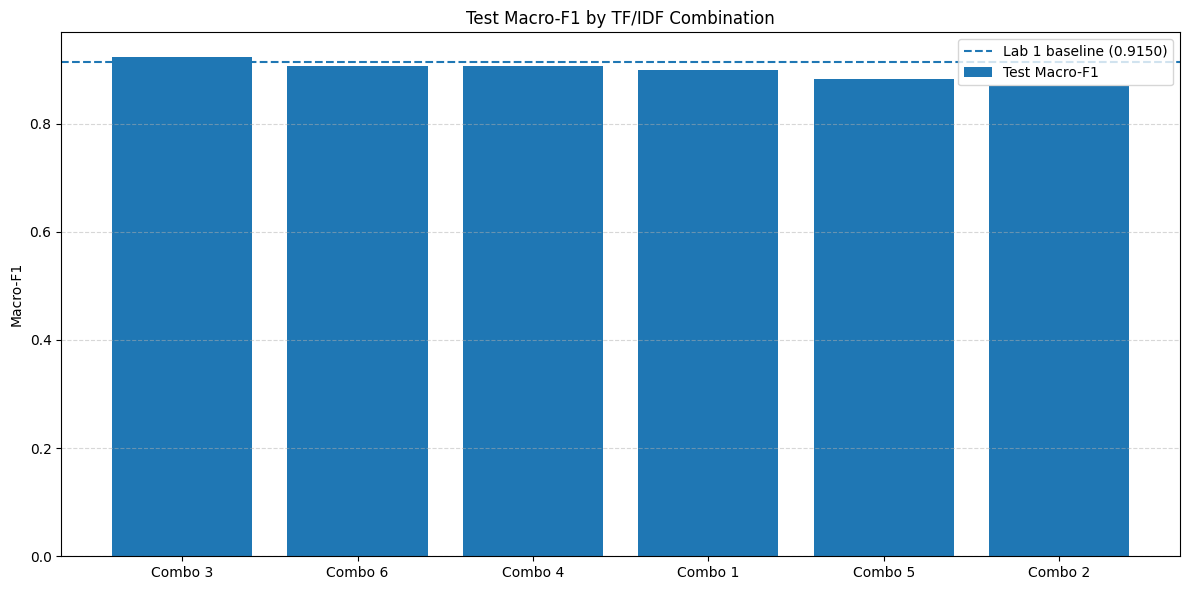

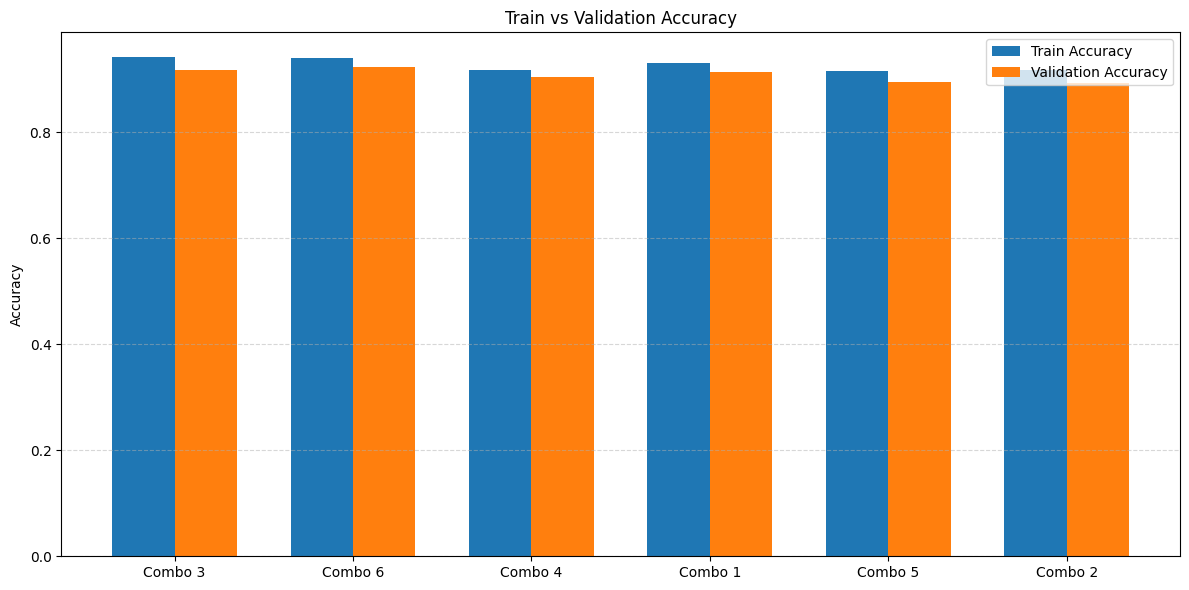

In [9]:
import matplotlib.pyplot as plt

display(
    results_df[
        ["Combo", "TF", "IDF",
         "Train Acc", "Val Acc", "Test Acc",
         "Val F1", "Test F1", "Overfit Gap"]
    ]
    .sort_values("Combo")
    .rename(columns={
        "TF": "TF Normalization",
        "IDF": "IDF Normalization",
        "Train Acc": "Train Accuracy",
        "Val Acc": "Validation Accuracy",
        "Test Acc": "Test Accuracy",
        "Val F1": "Validation Macro-F1",
        "Test F1": "Test Macro-F1",
        "Overfit Gap": "Train-Val Gap"
    })
    .round(4)
    .reset_index(drop=True)
)

x = np.arange(len(results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x, results_df["Test F1"], label="Test Macro-F1")
ax.axhline(0.9150, linestyle="--", label="Lab 1 baseline (0.9150)")
ax.set_ylabel("Macro-F1")
ax.set_title("Test Macro-F1 by TF/IDF Combination")
ax.set_xticks(x)
ax.set_xticklabels(
    [f"Combo {c}" for c in results_df["Combo"]]
)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width / 2, results_df["Train Acc"], width, label="Train Accuracy")
ax.bar(x + width / 2, results_df["Val Acc"], width, label="Validation Accuracy")
ax.set_ylabel("Accuracy")
ax.set_title("Train vs Validation Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(
    [f"Combo {c}" for c in results_df["Combo"]]
)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Conclusion & Key Findings

After running all six configurations:

1. Compare the three TF schemes:
   - Raw TF
   - TF normalized by total sentence words
   - TF normalized by maximum word frequency

2. Compare the two IDF schemes:
   - Standard smoothed IDF:
     `ln((1+N)/(1+df(t))) + 1`
   - IDF normalized using the most frequent word's training document frequency:
     `ln(M/df(t))`

3. Identify the best configuration using **test Macro-F1**, while also reporting
   validation performance and the train-validation accuracy gap.

4. Compare the best Lab 2 configuration with the Lab 1 baseline of 0.9150.

5. Do not interpret the result as a universal claim that one normalization is always better.
   The conclusion applies to this dataset, feature representation, classifier, and training setup.

**Important implementation choice:** No final row-wise L2 normalization is applied in Lab 2.
The reference `01_normalized_tfidf.ipynb` explicitly establishes that L2 normalization would
cancel the requested per-document TF rescaling and collapse the three TF variants into
effectively identical vectors.
